# NewsBot 2.0 · Notebook 05 – Multilingual Intelligence
**ITAI 2373 Final Project · Mourinho Hernanto**

**Goal:** detect languages with our own model, translate with MarianMT and assess quality, and compare how six languages cover the news (tone, entities, cultural context).

**Course modules:** 11 (MT & multilingual), 8 (NER)

> Runs top-to-bottom in Google Colab (first cell installs everything). All logic lives in `src/` –
> this notebook demonstrates and evaluates it.

In [1]:
# ⚙️ Setup – works in Google Colab (clones the repo + installs) and locally
import os, sys, subprocess
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
ROOT = Path("/content/ITAI2373-NewsBot-Final/ITAI2373-NewsBot-Final") if IN_COLAB else Path.cwd().resolve().parent
if IN_COLAB and not ROOT.exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/Haryapandhita/ITAI2373-NewsBot-Final.git",
                    "/content/ITAI2373-NewsBot-Final"], check=True)
sys.path.insert(0, str(ROOT))
from scripts.colab_setup import setup
ROOT = setup()

import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120)
# Transformer models (summarisation, translation, multilingual embeddings) are used when
# available (Colab: Runtime -> Change runtime type -> T4 GPU recommended); otherwise
# NewsBot falls back to classical methods automatically.
USE_TRANSFORMERS = os.environ.get("NEWSBOT_USE_TRANSFORMERS", "1") == "1"
print("Transformers enabled:", USE_TRANSFORMERS)

Project root: /home/claude/NewsBot-Final/ITAI2373-NewsBot-Final  |  Colab: False


Transformers enabled: True


In [2]:
from src.data_processing.data_loader import load_all
data = load_all(); webz = data["webz"]
webz["language"].value_counts()

language
en    8701
es    2257
de     634
pt     625
fr     537
it     459
Name: count, dtype: int64

## 1. Language detection – our own character n-gram model
TF-IDF over 1–4 character n-grams + logistic regression, trained on sentence snippets from 300 articles per language.
Evaluated on **unseen** articles and on very short inputs; `langdetect` is the baseline.

In [3]:
from src.multilingual.language_detector import LanguageDetector
train = webz.groupby("language").sample(300, random_state=42)
X, y = LanguageDetector.make_training_snippets(train.text, train.language)
det = LanguageDetector().train(X, y)
test = webz[~webz.doc_id.isin(train.doc_id)].groupby("language").sample(150, random_state=7)
pd.DataFrame(det.evaluate(test.text.tolist(), test.language.tolist())).T

20:50:48 | INFO    | src.multilingual.language_detector | Language detector trained on 5360 samples ({'de': 898, 'en': 890, 'es': 896, 'fr': 891, 'it': 889, 'pt': 896})


,accuracy,macro_f1
first_20_chars,0.7833,0.7817
first_50_chars,0.9433,0.9436
first_100_chars,0.9889,0.9890
first_300_chars,0.9967,0.9967
langdetect_baseline_first_100_chars,0.9767,NaN


In [4]:
for t in ["Breaking news", "Der Bundestag stimmt heute ab", "La Liga vuelve este fin de semana", "Il governo"]:
    print(f"{t!r:40} → {det.detect_language(t)}")

'Breaking news'                          → {'language': 'en', 'name': 'English', 'confidence': 0.8779, 'alternatives': {'de': 0.0761, 'pt': 0.019}, 'reliable': False}
'Der Bundestag stimmt heute ab'          → {'language': 'de', 'name': 'German', 'confidence': 0.8394, 'alternatives': {'en': 0.056, 'fr': 0.0428}, 'reliable': True}
'La Liga vuelve este fin de semana'      → {'language': 'und', 'name': 'Undetermined', 'confidence': 0.2729, 'alternatives': {'fr': 0.2343, 'es': 0.2224}, 'reliable': False}
'Il governo'                             → {'language': 'it', 'name': 'Italian', 'confidence': 0.7403, 'alternatives': {'en': 0.107, 'pt': 0.0976}, 'reliable': False}


In [5]:
det.detect_segments("The meeting was postponed until Friday. El presidente dijo que la economía crecerá. Die Börse reagierte positiv.")

{'mixed': True,
 'shares': {'en': 0.333, 'es': 0.333, 'de': 0.333},
 'segments': [{'sentence': 'The meeting was postponed until Friday.',
   'language': 'en',
   'confidence': 0.9527},
  {'sentence': 'El presidente dijo que la economía crecerá.',
   'language': 'es',
   'confidence': 0.9373},
  {'sentence': 'Die Börse reagierte positiv.',
   'language': 'de',
   'confidence': 0.6613}]}

## 2. Translation with MarianMT + reference-free quality estimate (round-trip chrF)

In [6]:
from src.multilingual.translator import Translator
tr = Translator(use_transformer=USE_TRANSFORMERS)
samples = webz[webz.language != "en"].groupby("language").sample(1, random_state=3)
rows = []
for _, r in samples.iterrows():
    out = tr.translate_text(r.title, r.language)
    q = tr.assess_quality(r.title, r.language, out["text"]) if out["translated"] else {}
    rows.append({"lang": r.language, "original": r.title, "english": out["text"], "engine": out["engine"],
                 "round_trip_chrF": q.get("round_trip_chrf")})
pd.DataFrame(rows)

20:50:50 | WARNING | src.multilingual.translator | Translation model Helsinki-NLP/opus-mt-de-en unavailable (No module named 'transformers')


20:50:50 | WARNING | src.multilingual.translator | Translation model Helsinki-NLP/opus-mt-es-en unavailable (No module named 'transformers')


20:50:50 | WARNING | src.multilingual.translator | Translation model Helsinki-NLP/opus-mt-fr-en unavailable (No module named 'transformers')


20:50:50 | WARNING | src.multilingual.translator | Translation model Helsinki-NLP/opus-mt-it-en unavailable (No module named 'transformers')


20:50:50 | WARNING | src.multilingual.translator | Translation model Helsinki-NLP/opus-mt-ROMANCE-en unavailable (No module named 'transformers')


,lang,original,english,engine,round_trip_chrF
0,de,"RWA-Perps-Volumen im August: 117 Mrd. $, +44x ggü. Vorjahr | Phemex News","RWA-Perps-Volumen im August: 117 Mrd. $, +44x ggü. Vorjahr | Phemex News",unavailable,None
1,es,U. de Chile desarrolla nueva tecnología para captar señales del Universo - DAS - Universidad de Chile,U. de Chile desarrolla nueva tecnología para captar señales del Universo - DAS - Universidad de Chile,unavailable,None
2,fr,"Molotov victime d’un vol de données : 10,8 millions de comptes concernés","Molotov victime d’un vol de données : 10,8 millions de comptes concernés",unavailable,None
3,it,"Gazzetta: ""Fiorentina, il pareggio accontenta Sarri. Pellegrino innocuo e friabile""","Gazzetta: ""Fiorentina, il pareggio accontenta Sarri. Pellegrino innocuo e friabile""",unavailable,None
4,pt,PS questiona Governo sobre “inação da AICEP” e medidas a adotar para a resolver – Observador,PS questiona Governo sobre “inação da AICEP” e medidas a adotar para a resolver – Observador,unavailable,None


## 3. Cross-lingual comparison

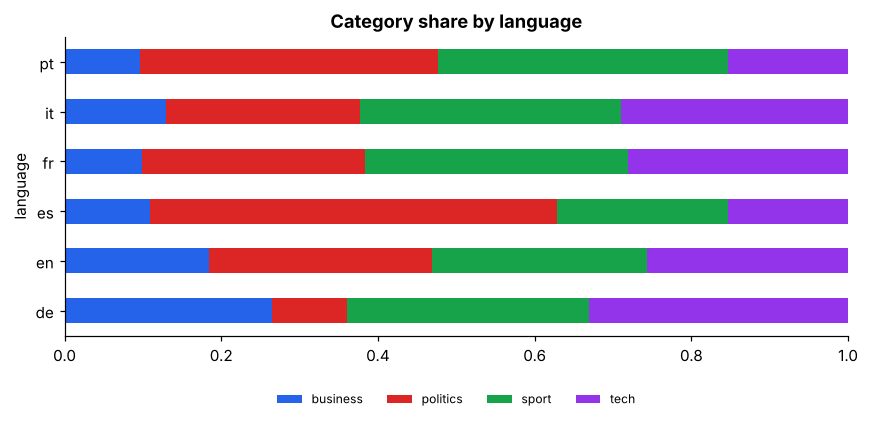

In [7]:
from src.analysis.ner_extractor import EntityRelationshipMapper
from src.multilingual.cross_lingual_analyzer import CrossLingualAnalyzer
mapper = EntityRelationshipMapper()
w = webz.copy()
w["entities"] = mapper.corpus_entities((w.title + ". " + w.text).tolist(), w.language.tolist())
cla = CrossLingualAnalyzer(w)
from src.utils import visualization as viz
viz.stacked_share(cla.coverage_by_language(), "Category share by language"); plt.show()

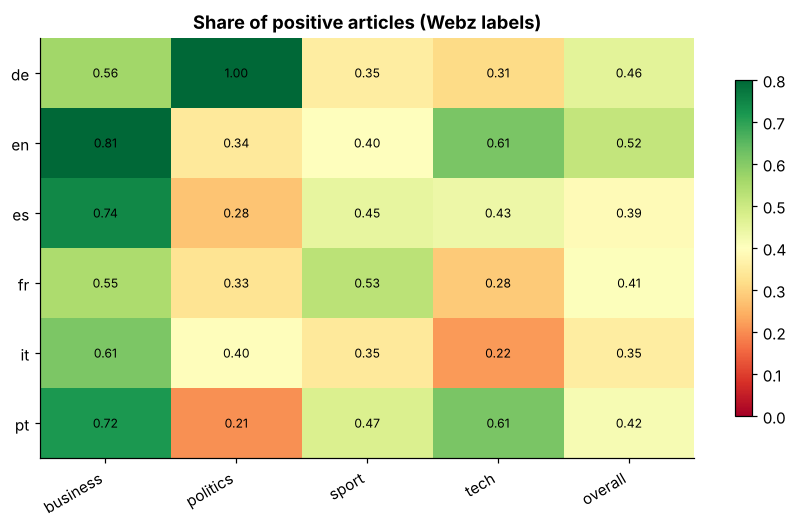

In [8]:
viz.heatmap(cla.sentiment_by_language().drop(columns="n"), "Share of positive articles (Webz labels)", vmin=0, vmax=0.8); plt.show()

In [9]:
pd.DataFrame({l: [f"{e} ({c})" for e, c in v] for l, v in cla.entities_by_language(10).items()})

,de,en,es,fr,it,pt
0,United States (45),United States (1157),United States (175),France (42),United States (40),Brazil (91)
1,CVSS (44),Donald Trump (474),Estado (131),Paris (33),Italy (30),Lula (46)
2,Sicherheitspatches (44),AI (417),Spain (122),United States (32),Roma (27),United States (45)
3,Bundesamt für Sicherheit (44),India (342),Gobierno (113),Donald Trump (23),Napoli (25),Estado (43)
4,BSI (44),Joe Biden (331),Mexico (105),Liverpool (22),Google (24),São Paulo (36)
5,Sicherheitslücke (44),United Kingdom (280),PP (103),PSG (22),Milan (23),Liverpool (32)
6,Risikostufe (41),China (277),Congreso (94),Manchester United (18),Donald Trump (22),Brasília (29)
7,Base Score (38),Washington (224),Donald Trump (91),West Ham (16),Juventus (21),Luiz Inácio Lula da Silva (29)
8,Germany (35),Republican (205),Ukraine (69),Français (15),Paese (18),PT (27)
9,Donald Trump (32),Russia (194),Europa (67),RN (15),Comune (18),Manchester United (27)


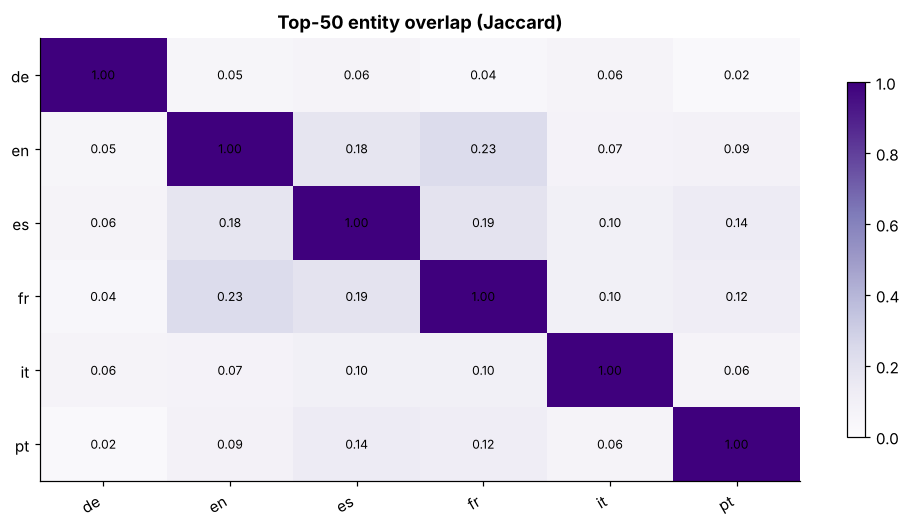

In [10]:
viz.heatmap(cla.entity_overlap(50), "Top-50 entity overlap (Jaccard)", cmap="Purples", vmin=0, vmax=1); plt.show()

## 4. Regional perspectives on the same entity

In [11]:
for e in ["Donald Trump", "China", "Ukraine"]:
    print("==", e); display(cla.perspective_on(e))

== Donald Trump


,language,articles,share_of_language,positive_share,top_co_mentions
0,en,474,0.0545,0.232,"United States, Joe Biden, Republican, Kamala Harris, CNN"
1,es,91,0.0403,0.363,"United States, Joe Biden, Kamala Harris, Washington, Casa Blanca"
2,de,32,0.0505,0.312,"United States, China, Trump-Krise, London, US-Routen"
3,fr,23,0.0428,0.348,"Joe Biden, Washington, United States, Kamala Harris, Elon Musk"
4,it,22,0.0479,0.318,"United States, Elon Musk, l'Iran, Italy, Adnkronos"
5,pt,20,0.0320,0.150,"United States, Irã, Nova, Leia, Real Madrid"


== China


,language,articles,share_of_language,positive_share,top_co_mentions
0,en,277,0.0318,0.520,"United States, Chinese, Beijing, Russia, Donald Trump"
1,es,43,0.0191,0.465,"Russia, United States, Ukraine, India, Asia"
2,de,25,0.0394,0.280,"United States, Donald Trump, Frankfurt, Trump-Krise, London"
3,it,10,0.0218,0.300,"United States, Japan, Australia, Europa, United Kingdom"
4,fr,7,0.0130,0.429,"la Chine, La Chine, Hang Seng, Trip.com Group Ltd, L’entreprise"
5,pt,6,0.0096,0.500,"Brazil, Russia, Índia, Brics, África do Sul"


== Ukraine


,language,articles,share_of_language,positive_share,top_co_mentions
0,en,170,0.0195,0.459,"Russia, Russian, United States, NATO, Washington"
1,es,69,0.0306,0.232,"Russia, United States, Vladimir Putin, NATO, Kiev"
2,de,12,0.0189,0.833,"European Union, EU-Kommissionspräsidentin, Friedrich Merz, Europäischen Parlament, Europäischen Union"
3,pt,10,0.0160,0.300,"Russia, Estado, Marine Le Pen, RN, Extrema"
4,fr,9,0.0168,0.333,"TVA Montréal, Canadiens, Saguenay-Lac-St-Jean TVA Est-du-Québec Populaires, Info Patrouille Judiciaire Politique Int..."
5,it,8,0.0174,0.000,"Russia, Kiev, Mosca, United States, Volodymyr Zelensky"


## 5. The same story in different languages (entity overlap + 7-day window)

In [12]:
cla.link_stories(min_shared=3, window_days=7, max_links=10)

,lang_a,title_a,lang_b,title_b,shared_entities,n_shared,days_apart
0,es,Williams y Gillespie llevan a Suns a victoria 112-100 sobre Kings y a foja de 3-0 en Copa,en,Williams and Gillespie power Suns to a 112-100 win over Kings and improve to 3-0 in NBA Cu,"Collin Gillespie, Devin Booker, Gillespie, Keegan Murray, Malik Monk, Mark Williams",12,1
1,fr,De nouvelles sanctions à l’encontre des actes de violence commis par des colons extrémiste,es,"Canadá impone una segunda ronda de sanciones contra colonos israelíes ""extremistas"" - Info","Ben Zion Gopstein, Daniella Weiss, Einan Ben-Nir Amram Tanjil, Elisha Yered, Ely Federman, Farm",12,1
2,es,"Arsenal cae 2-0 en casa ante West Ham, Liverpool líder en firme | El Nuevo Siglo",pt,"Arsenal perde em casa para West Ham, e Liverpool é líder do Inglês","Aston Villa, Brighton, Emirates Stadium, Everton, Gunners, Hammers",11,1
3,es,Resumen: Triplete de Amad Diallo en el triunfo de Manchester United ante Southampton por 3,en,Amad's the man as Man United comeback stuns Southampton | Flashscore.co.uk,"Alejandro Garnacho, André Onana, Kamaldeen Sulemana, Kobbie Mainoo, Leny Yoro, Manuel Ugarte",11,0
4,en,Amad's the man as Man United comeback stuns Southampton | Flashscore.co.uk,es,Triplete de Amad Diallo en el triunfo de Manchester United ante Southampton por 3-1 | Prem,"Alejandro Garnacho, André Onana, Kamaldeen Sulemana, Kobbie Mainoo, Leny Yoro, Manuel Ugarte",11,1
5,en,"Alejo Véliz scored his first goal for Tottenham, who are struggling without Cuti Romero: L",es,"Alejo Véliz convirtió su primer gol en el Tottenham, que sufre sin Cuti Romero: Lo Celso h","Alejo Véliz, Ben Davies, Brighton, Cuti Romero, Facundo Buonanotte, Gio Lo Celso",11,0
6,pt,Amazon vai lançar primeiros satélites para concorrer com Starlink,es,Amazon lanzará sus primeros satélites rivales de Starlink,"Amazon, Boeing, Elon Musk, Eutelsat, Jeff Bezos, Lockheed Martin",10,1
7,pt,Amazon vai lançar primeiros satélites para concorrer com Starlink,es,Amazon lanzará sus primeros satélites rivales de Starlink | El Nuevo Siglo,"Amazon, Boeing, Elon Musk, Eutelsat, Jeff Bezos, Lockheed Martin",10,0
8,es,Amazon lanzará sus primeros satélites rivales de Starlink,pt,Amazon vai lançar primeiros satélites para concorrer com Starlink,"Amazon, Boeing, Elon Musk, Eutelsat, Jeff Bezos, Lockheed Martin",10,0
9,es,Amazon lanzará sus primeros satélites rivales de Starlink | El Nuevo Siglo,pt,Amazon vai lançar primeiros satélites para concorrer com Starlink,"Amazon, Boeing, Elon Musk, Eutelsat, Jeff Bezos, Lockheed Martin",10,1


## 6. Cultural context

In [13]:
display(cla.country_focus())
for lang in ["es", "de", "fr", "pt"]:
    t = webz[webz.language == lang].text
    hits = [CrossLingualAnalyzer.extract_cultural_context(x, lang) for x in t.head(300)]
    refs = pd.Series([k for h in hits for k in h["references"]]).value_counts().head(5)
    print(lang, dict(refs))

,language,articles_with_country,home_country_share,top_source_countries
0,de,624,0.883,"DE, VN, AT, CH"
1,en,8630,0.813,"US, IN, GB, CA"
2,es,2253,0.774,"ES, AR, MX, US"
3,fr,529,0.788,"FR, BE, CA, VN"
4,it,459,0.932,"IT, US, CH,"
5,pt,620,0.835,"BR, PT, IT, US"


es {'PSOE': np.int64(10), 'PP': np.int64(9), 'Wall Street': np.int64(5), 'AMLO': np.int64(5), 'Premier League': np.int64(4)}


de {'CDU': np.int64(25), 'SPD': np.int64(18), 'Fed': np.int64(8), 'AfD': np.int64(6), 'Bundestag': np.int64(4)}


fr {'RN': np.int64(17), 'Assemblée nationale': np.int64(13), 'Matignon': np.int64(6), 'Fed': np.int64(3), 'Élysée': np.int64(2)}


pt {'Lula': np.int64(65), 'STF': np.int64(24), 'Planalto': np.int64(10), 'Brasileirão': np.int64(4), 'Ibovespa': np.int64(2)}


## Key takeaways
* Our own language detector is near-perfect on articles and stays strong on very short snippets, matching or beating `langdetect`.
* MarianMT (Colab) translates titles/articles locally; round-trip chrF gives a quality signal without references.
* Languages differ clearly in **what** they cover (Spanish: politics-heavy, German: tech-heavy) and **how** (share of
  positive articles, entity focus). Multilingual aliases (*Estados Unidos*, *Alemania* → canonical names) make entities comparable.
* Cultural references (Bundestag, Moncloa, Ibovespa…) are detected and explained for international readers.